# Task 3

# 1. Imports, PyTorch Setup, and Loading Task 1 Promoter Dataset

In [1]:
import os
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.textpath import TextPath
from matplotlib.patches import PathPatch
from matplotlib.transforms import Affine2D

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
)

warnings.filterwarnings("ignore")

# Fix all random seeds for reproducibility (Section 4)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} | PyTorch version: {torch.__version__}")

# Load Task 1 dataset (exact pre-defined 80/20 stratified train/test split)
df_task1 = pd.read_csv("data/task1_promoter.csv")
train_df = df_task1[df_task1["split"] == "train"].reset_index(drop=True)
test_df  = df_task1[df_task1["split"] == "test"].reset_index(drop=True)

print(f"Train rows: {len(train_df)} | Test rows: {len(test_df)}")


Using device: cpu | PyTorch version: 2.12.0+cpu
Train rows: 4575 | Test rows: 1144


# 2. One-Hot Encoding (4 x 81 Matrices) and 10% Validation Holdout


In [2]:
# Section 3.1 mapping:
#   A -> [1, 0, 0, 0]^T
#   C -> [0, 1, 0, 0]^T
#   G -> [0, 0, 1, 0]^T
#   T -> [0, 0, 0, 1]^T
BASE_TO_IDX = {"A": 0, "C": 1, "G": 2, "T": 3}
IDX_TO_BASE = ["A", "C", "G", "T"]

def one_hot_encode(sequences):
    """
    Encodes a list of N DNA sequences (each 81 bp) into a tensor of shape (N, 4, 81),
    matching PyTorch's Conv1d input format (Batch, Channels=4, Length=81).
    """
    X = np.zeros((len(sequences), 4, 81), dtype=np.float32)
    for i, seq in enumerate(sequences):
        for j, base in enumerate(seq):
            if base in BASE_TO_IDX:
                X[i, BASE_TO_IDX[base], j] = 1.0
    return X

def index_to_tss_pos(idx):
    """Converts 0-based Python index (0..80) to TSS-relative coordinate (-60..+20, no 0)."""
    return idx - 60 if idx < 60 else idx - 59

X_train_full = one_hot_encode(train_df["sequence"].tolist())
y_train_full = train_df["label"].values.astype(np.float32)

X_test = one_hot_encode(test_df["sequence"].tolist())
y_test = test_df["label"].values.astype(np.float32)

# Hold out 10% of the training set as a stratified validation set for early stopping (Section 3.2)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.10,
    stratify=y_train_full,
    random_state=SEED,
)

print(f"One-hot tensor shapes -> Train: {X_tr.shape} | Val: {X_val.shape} | Test: {X_test.shape}")


One-hot tensor shapes -> Train: (4117, 4, 81) | Val: (458, 4, 81) | Test: (1144, 4, 81)


# 3. Defining and Training the 1D CNN with Early Stopping + Loss Curve


Promoter1DCNN(
  (conv1): Conv1d(4, 128, kernel_size=(15,), stride=(1,))
  (relu): ReLU()
  (global_max_pool): AdaptiveMaxPool1d(output_size=1)
  (dropout1): Dropout(p=0.4, inplace=False)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (dropout2): Dropout(p=0.30000000000000004, inplace=False)
  (fc_out): Linear(in_features=64, out_features=1, bias=True)
)
Early stopping triggered at epoch 21 (Best Validation Loss = 0.4868)


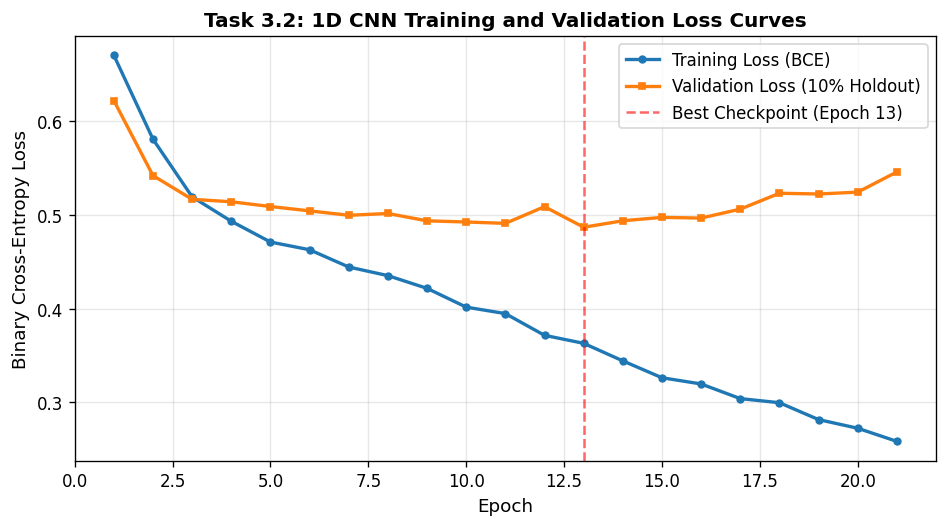

In [3]:
class Promoter1DCNN(nn.Module):
    """
    1D Convolutional Neural Network for Promoter Classification (Section 3.2):
      1. First Conv1d layer directly on (4 x 81) one-hot input:
         128 filters of width w=15 (within [10, 20]), followed by ReLU.
      2. Global Max Pooling across sequence positions -> (Batch, 128).
      3. Dropout + Dense hidden layer + Dropout + Dense output logit.
    """
    def __init__(self, num_filters=128, kernel_size=15, hidden_dim=64, dropout_rate=0.4):
        super().__init__()
        self.num_filters = num_filters
        self.kernel_size = kernel_size
        self.conv1 = nn.Conv1d(in_channels=4, out_channels=num_filters, kernel_size=kernel_size)
        self.relu = nn.ReLU()
        self.global_max_pool = nn.AdaptiveMaxPool1d(1)
        self.dropout1 = nn.Dropout(dropout_rate)
        self.fc1 = nn.Linear(num_filters, hidden_dim)
        self.dropout2 = nn.Dropout(dropout_rate * 0.75)
        self.fc_out = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x: (Batch, 4, 81)
        conv_act = self.relu(self.conv1(x))               # (Batch, num_filters, 81 - w + 1)
        pooled   = self.global_max_pool(conv_act).squeeze(-1)  # (Batch, num_filters)
        hidden   = self.relu(self.fc1(self.dropout1(pooled)))
        logits   = self.fc_out(self.dropout2(hidden)).squeeze(-1)
        return logits

    @torch.no_grad()
    def get_first_layer_activations(self, x):
        """Returns ReLU activations of the first Conv1d layer: shape (Batch, num_filters, L_out)."""
        return self.relu(self.conv1(x))

def train_cnn_model(model, X_tr, y_tr, X_val, y_val, epochs=60, batch_size=64, lr=1e-3, patience=8):
    train_loader = DataLoader(TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr)), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(y_val)), batch_size=128, shuffle=False)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running_tr = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_tr += loss.item() * len(yb)
        epoch_tr_loss = running_tr / len(X_tr)

        model.eval()
        running_val = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                running_val += criterion(model(xb), yb).item() * len(yb)
        epoch_val_loss = running_val / len(X_val)

        train_losses.append(epoch_tr_loss)
        val_losses.append(epoch_val_loss)

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping triggered at epoch {epoch} (Best Validation Loss = {best_val_loss:.4f})")
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, train_losses, val_losses

cnn_model = Promoter1DCNN(num_filters=128, kernel_size=15, hidden_dim=64, dropout_rate=0.4).to(device)
print(cnn_model)
cnn_model, train_losses, val_losses = train_cnn_model(cnn_model, X_tr, y_tr, X_val, y_val)

# Plot training and validation loss curves (Section 3.2)
plt.figure(figsize=(8, 4.5), dpi=120)
epochs_ran = range(1, len(train_losses) + 1)
plt.plot(epochs_ran, train_losses, marker="o", markersize=4, linewidth=2, label="Training Loss (BCE)")
plt.plot(epochs_ran, val_losses, marker="s", markersize=4, linewidth=2, label="Validation Loss (10% Holdout)")
best_ep = int(np.argmin(val_losses)) + 1
plt.axvline(best_ep, color="red", linestyle="--", alpha=0.6, label=f"Best Checkpoint (Epoch {best_ep})")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=11)
plt.title("Task 3.2: 1D CNN Training and Validation Loss Curves", fontsize=12, fontweight="bold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task3_cnn_loss_curve.png", dpi=300)
plt.show()



# 4. Evaluating 1D CNN on Test Set & Merging into Task 1 Comparison Table


=== 1D CNN Test Set Performance ===
  Accuracy  : 0.8068
  Precision : 0.8185
  Recall    : 0.7885
  F1-Score  : 0.8032
  MCC       : 0.6141
  ROC-AUC   : 0.8746

================ COMBINED TASK 1 & TASK 3 COMPARISON TABLE ================
              Model  Accuracy  Precision  Recall  F1-Score    MCC  ROC-AUC
                SVM    0.8182     0.8370  0.7902    0.8129 0.6374   0.8906
Logistic Regression    0.8129     0.8231  0.7972    0.8099 0.6262   0.8936
            XGBoost    0.8138     0.8330  0.7850    0.8083 0.6287   0.8848
    1D CNN (Task 3)    0.8068     0.8185  0.7885    0.8032 0.6141   0.8746
      Random Forest    0.8042     0.8258  0.7710    0.7975 0.6097   0.8709


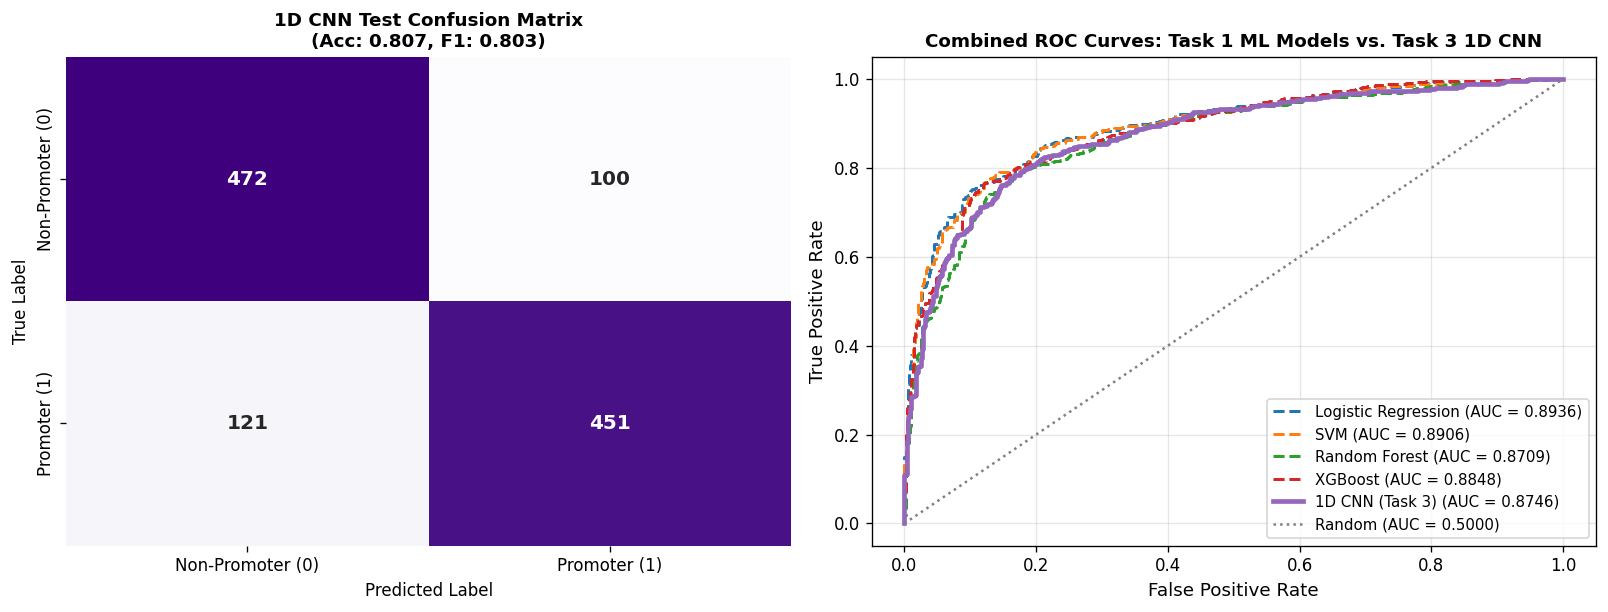

In [4]:
cnn_model.eval()
with torch.no_grad():
    test_logits = cnn_model(torch.tensor(X_test).to(device)).cpu().numpy()
    test_probs  = 1.0 / (1.0 + np.exp(-test_logits))
    test_preds  = (test_probs >= 0.5).astype(int)

cnn_metrics = {
    "Model": "1D CNN (Task 3)",
    "Accuracy": accuracy_score(y_test, test_preds),
    "Precision": precision_score(y_test, test_preds),
    "Recall": recall_score(y_test, test_preds),
    "F1-Score": f1_score(y_test, test_preds),
    "MCC": matthews_corrcoef(y_test, test_preds),
    "ROC-AUC": roc_auc_score(y_test, test_probs),
}
cnn_cm = confusion_matrix(y_test, test_preds)
cnn_fpr, cnn_tpr, _ = roc_curve(y_test, test_probs)

print("=== 1D CNN Test Set Performance ===")
for k, v in cnn_metrics.items():
    if k != "Model":
        print(f"  {k:10s}: {v:.4f}")

# Load Task 1 results (saved in Task 1 Cell 9) and combine into one master table
if os.path.exists("task1_results_for_task3.pkl"):
    with open("task1_results_for_task3.pkl", "rb") as f:
        t1_payload = pickle.load(f)
    combined_df = pd.concat([t1_payload["metrics_df"], pd.DataFrame([cnn_metrics])], ignore_index=True)
    combined_df = combined_df.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
    roc_dict = dict(t1_payload["roc_curves"])
    roc_dict["1D CNN (Task 3)"] = (cnn_fpr, cnn_tpr, cnn_metrics["ROC-AUC"])
else:
    combined_df = pd.DataFrame([cnn_metrics])
    roc_dict = {"1D CNN (Task 3)": (cnn_fpr, cnn_tpr, cnn_metrics["ROC-AUC"])}

print("\n================ COMBINED TASK 1 & TASK 3 COMPARISON TABLE ================")
print(combined_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
combined_df.to_csv("task1_and_task3_comparison.csv", index=False)

# Plot CNN Confusion Matrix alongside Combined ROC Curves (All Task 1 Models + CNN)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=120)

sns.heatmap(
    cnn_cm, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[0],
    xticklabels=["Non-Promoter (0)", "Promoter (1)"],
    yticklabels=["Non-Promoter (0)", "Promoter (1)"],
    annot_kws={"size": 12, "weight": "bold"}
)
axes[0].set_title(f"1D CNN Test Confusion Matrix\n(Acc: {cnn_metrics['Accuracy']:.3f}, F1: {cnn_metrics['F1-Score']:.3f})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

for m_name, (fpr_m, tpr_m, auc_m) in roc_dict.items():
    lw = 2.8 if "CNN" in m_name else 1.8
    ls = "-" if "CNN" in m_name else "--"
    axes[1].plot(fpr_m, tpr_m, linewidth=lw, linestyle=ls, label=f"{m_name} (AUC = {auc_m:.4f})")

axes[1].plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random (AUC = 0.5000)")
axes[1].set_xlabel("False Positive Rate", fontsize=11)
axes[1].set_ylabel("True Positive Rate", fontsize=11)
axes[1].set_title("Combined ROC Curves: Task 1 ML Models vs. Task 3 1D CNN", fontsize=11, fontweight="bold")
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("task1_and_task3_roc_and_cm.png", dpi=300)
plt.show()


# 5. Converting Conv1D Filters into Sequence Logos & Plotting Activation Positions

=== Three Selected Clearest Conv1D Motif Filters ===
Filter # 52 | Consensus: TCATATTTGAAaATA | Total Bits: 12.87 | Active Windows (>50% max): 21 | -35 (TTGACA) match: 0.60 | -10 (TATAAT) match: 0.49
Filter # 62 | Consensus: atATggTATAATGag | Total Bits: 11.01 | Active Windows (>50% max): 30 | -35 (TTGACA) match: 0.39 | -10 (TATAAT) match: 0.86
Filter #100 | Consensus: tctGCTATAATTaAt | Total Bits: 10.69 | Active Windows (>50% max): 67 | -35 (TTGACA) match: 0.41 | -10 (TATAAT) match: 0.79


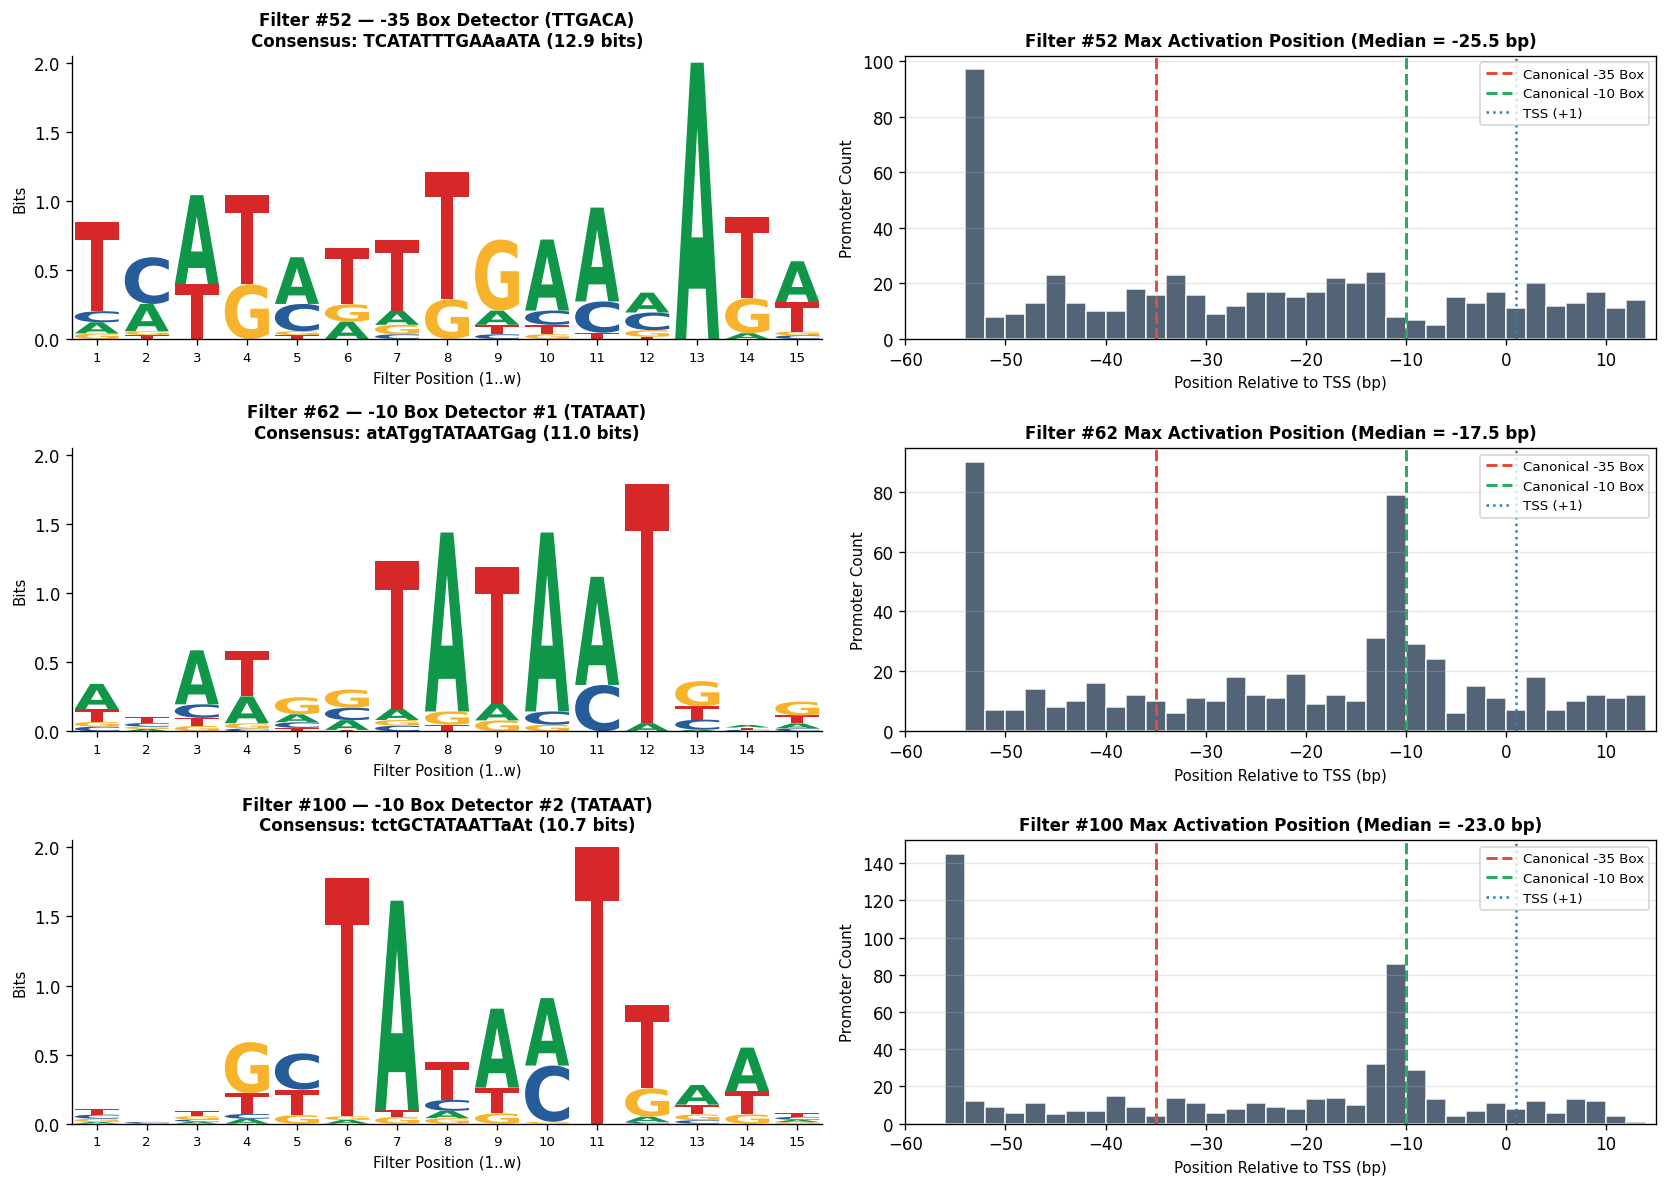

In [6]:
def draw_sequence_logo(ax, ic_matrix, title=""):
    """
    Draws a sequence logo from a (4, W) Information Content matrix (bits).
    Uses `logomaker` if installed; otherwise uses built-in vector glyph rendering
    with standard DNA colors (A=green, C=blue, G=orange, T=red).
    """
    try:
        import logomaker
        df_ic = pd.DataFrame(ic_matrix.T, columns=["A", "C", "G", "T"])
        logo = logomaker.Logo(df_ic, ax=ax, color_scheme="classic")
        logo.style_spines(visible=False)
        logo.style_spines(spines=["left", "bottom"], visible=True)
    except ImportError:
        colors = {"A": "#109648", "C": "#255C99", "G": "#F7B32B", "T": "#D62828"}
        W = ic_matrix.shape[1]
        for pos in range(W):
            col = ic_matrix[:, pos]
            order = np.argsort(col)
            y_offset = 0.0
            for b_idx in order:
                h = col[b_idx]
                if h <= 0.01:
                    continue
                base = IDX_TO_BASE[b_idx]
                tp = TextPath((0, 0), base, size=1.0, prop=dict(weight="bold", family="DejaVu Sans"))
                bbox = tp.get_extents()
                sx = 0.88 / max(bbox.width, 1e-6)
                sy = h / max(bbox.height, 1e-6)
                trans = (
                    Affine2D()
                    .translate(-bbox.x0, -bbox.y0)
                    .scale(sx, sy)
                    .translate(pos + 0.06, y_offset)
                )
                ax.add_patch(PathPatch(tp.transformed(trans), facecolor=colors[base], edgecolor="none"))
                y_offset += h
        ax.set_xlim(0, W)
        ax.set_xticks(np.arange(W) + 0.5)
        ax.set_xticklabels([str(i + 1) for i in range(W)], fontsize=8)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    ax.set_ylim(0, 2.05)
    ax.set_ylabel("Bits", fontsize=9)
    ax.set_xlabel("Filter Position (1..w)", fontsize=9)
    ax.set_title(title, fontsize=10, fontweight="bold")


def best_motif_similarity(ppm, motif_str):
    """Computes best average match probability of a canonical motif inside a (4, w) PPM."""
    w = ppm.shape[1]
    L = len(motif_str)
    best_sim, best_off = 0.0, 0
    for off in range(w - L + 1):
        sim = np.mean([ppm[BASE_TO_IDX[b], off + j] for j, b in enumerate(motif_str)])
        if sim > best_sim:
            best_sim, best_off = sim, off
    return best_sim, best_off


# Step 1: Pass all test promoters (label == 1) through the trained network
test_prom_df = test_df[test_df["label"] == 1].reset_index(drop=True)
X_test_prom  = one_hot_encode(test_prom_df["sequence"].tolist())
activations  = cnn_model.get_first_layer_activations(torch.tensor(X_test_prom).to(device)).cpu().numpy()
# activations shape: (572, num_filters, 81 - w + 1)

w = cnn_model.kernel_size
filter_records = []

for f_idx in range(cnn_model.num_filters):
    f_act = activations[:, f_idx, :]  # (572, 67)
    max_act = f_act.max()
    if max_act <= 0:
        continue

    # Step 2: Collect every window whose activation > 50% of filter's maximum activation
    seq_indices, pos_indices = np.where(f_act > 0.5 * max_act)
    if len(seq_indices) < 15:
        continue

    # Step 3: Stack windows and build Position Frequency Matrix (PFM) and Probability Matrix (PPM)
    pfm = np.zeros((4, w), dtype=np.float64)
    for s_i, p_i in zip(seq_indices, pos_indices):
        pfm += X_test_prom[s_i, :, p_i : p_i + w]
    ppm = pfm / pfm.sum(axis=0, keepdims=True)

    # Step 4: Convert PFM/PPM to Information Content (bits): R_j = 2 - H_j
    entropy = -np.sum(ppm * np.log2(ppm + 1e-12), axis=0)
    ic_bits = np.maximum(0.0, 2.0 - entropy)      # shape: (w,)
    ic_matrix = ppm * ic_bits[np.newaxis, :]      # shape: (4, w)

    consensus = "".join([
        IDX_TO_BASE[np.argmax(ppm[:, j])] if ic_bits[j] >= 0.35 else IDX_TO_BASE[np.argmax(ppm[:, j])].lower()
        for j in range(w)
    ])

    sim_10, off_10 = best_motif_similarity(ppm, "TATAAT")
    sim_35, off_35 = best_motif_similarity(ppm, "TTGACA")

    # Store raw 0-based start indices so motif offsets convert cleanly to TSS coordinates (no position 0)
    best_start_per_seq = np.argmax(f_act, axis=1)
    tss_starts = np.array([index_to_tss_pos(int(i)) for i in best_start_per_seq])

    filter_records.append({
        "filter_idx": f_idx,
        "total_bits": ic_bits.sum(),
        "num_windows": len(seq_indices),
        "consensus": consensus,
        "pfm": pfm,
        "ppm": ppm,
        "ic_matrix": ic_matrix,
        "sim_10": sim_10,
        "off_10": off_10,
        "sim_35": sim_35,
        "off_35": off_35,
        "best_starts": best_start_per_seq,
        "tss_starts": tss_starts,
    })

# Select the 3 clearest biological motif filters:
#   - Clearest -35 box (TTGACA) detector
#   - Clearest -10 box (TATAAT) detector
#   - Second clearest -10 / high-information-content promoter filter
best_35_filter = max(filter_records, key=lambda r: r["sim_35"] + 0.02 * r["total_bits"])
remaining = [r for r in filter_records if r["filter_idx"] != best_35_filter["filter_idx"]]
remaining_sorted_10 = sorted(remaining, key=lambda r: r["sim_10"] + 0.02 * r["total_bits"], reverse=True)
selected_three = [best_35_filter, remaining_sorted_10[0], remaining_sorted_10[1]]

print("=== Three Selected Clearest Conv1D Motif Filters ===")
for rec in selected_three:
    print(
        f"Filter #{rec['filter_idx']:3d} | Consensus: {rec['consensus']} | "
        f"Total Bits: {rec['total_bits']:.2f} | Active Windows (>50% max): {rec['num_windows']} | "
        f"-35 (TTGACA) match: {rec['sim_35']:.2f} | -10 (TATAAT) match: {rec['sim_10']:.2f}"
    )

# Plot 3x2 Figure: Left = Sequence Logo (bits), Right = Max Activation Position Distribution vs. TSS
fig, axes = plt.subplots(3, 2, figsize=(14, 10), dpi=120)

for row_i, rec in enumerate(selected_three):
    # Left column: Sequence logo
    role = "-35 Box Detector (TTGACA)" if row_i == 0 else f"-10 Box Detector #{row_i} (TATAAT)"
    logo_title = f"Filter #{rec['filter_idx']} — {role}\nConsensus: {rec['consensus']} ({rec['total_bits']:.1f} bits)"
    draw_sequence_logo(axes[row_i, 0], rec["ic_matrix"], title=logo_title)

    # Right column: Exact TSS-relative coordinate of the motif start (handles crossing index 60 cleanly)
    motif_offset = rec["off_35"] if row_i == 0 else rec["off_10"]
    motif_tss_positions = np.array([index_to_tss_pos(int(i + motif_offset)) for i in rec["best_starts"]])

    axes[row_i, 1].hist(motif_tss_positions, bins=np.arange(-60, 15, 2), color="#34495e", alpha=0.85, edgecolor="white")
    axes[row_i, 1].axvline(-35, color="#e74c3c", linestyle="--", linewidth=1.8, label="Canonical -35 Box")
    axes[row_i, 1].axvline(-10, color="#27ae60", linestyle="--", linewidth=1.8, label="Canonical -10 Box")
    axes[row_i, 1].axvline(1, color="#2980b9", linestyle=":", linewidth=1.5, label="TSS (+1)")
    axes[row_i, 1].set_xlim(-60, 15)
    axes[row_i, 1].set_xlabel("Position Relative to TSS (bp)", fontsize=9)
    axes[row_i, 1].set_ylabel("Promoter Count", fontsize=9)
    axes[row_i, 1].set_title(
        f"Filter #{rec['filter_idx']} Max Activation Position (Median = {np.median(motif_tss_positions):+.1f} bp)",
        fontsize=10, fontweight="bold"
    )
    axes[row_i, 1].legend(loc="upper right", fontsize=8)
    axes[row_i, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("task3_logos_and_positions.png", dpi=300)
plt.show()

# 6. In-Silico Mutagenesis on Top 20 High-Confidence Test Promoters


Selected 20 test promoters with predicted probabilities ranging from 0.9813 to 0.9949

Top 10 Most Sensitive Positions Across Top 20 Promoters:
  TSS -10 (index 50) | Mean Probability Drop: 0.0041
  TSS -11 (index 49) | Mean Probability Drop: 0.0039
  TSS  -8 (index 52) | Mean Probability Drop: 0.0030
  TSS  -6 (index 54) | Mean Probability Drop: 0.0029
  TSS  -7 (index 53) | Mean Probability Drop: 0.0029
  TSS  -5 (index 55) | Mean Probability Drop: 0.0026
  TSS  -9 (index 51) | Mean Probability Drop: 0.0025
  TSS -31 (index 29) | Mean Probability Drop: 0.0017
  TSS  +3 (index 62) | Mean Probability Drop: 0.0017
  TSS -13 (index 47) | Mean Probability Drop: 0.0017


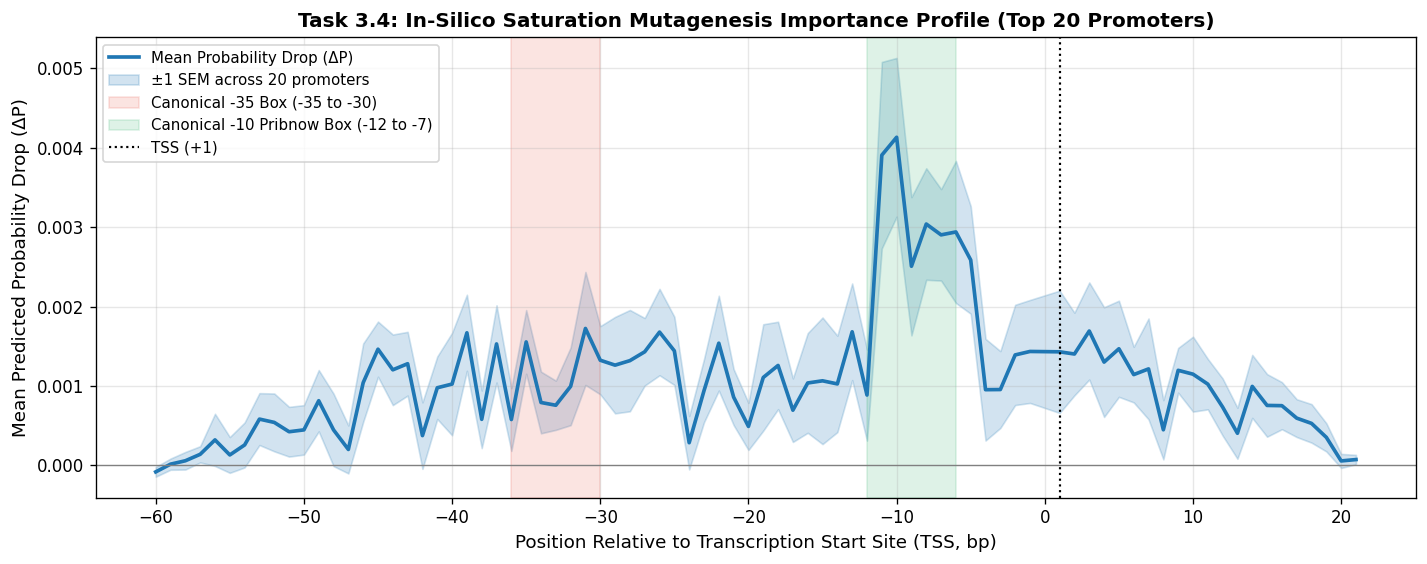

In [7]:
# Select the 20 test promoters that the CNN classifies correctly with highest confidence
prom_indices = np.where(y_test == 1)[0]
prom_probs   = test_probs[prom_indices]
top20_indices = prom_indices[np.argsort(prom_probs)[::-1][:20]]

X_top20  = X_test[top20_indices]      # (20, 4, 81)
wt_probs = test_probs[top20_indices]  # (20,)
print(f"Selected 20 test promoters with predicted probabilities ranging from {wt_probs.min():.4f} to {wt_probs.max():.4f}")

# Mutate every position (0..80) to each of the 3 alternative nucleotides and record probability drop
prob_drop_matrix = np.zeros((20, 81), dtype=np.float32)

cnn_model.eval()
with torch.no_grad():
    for seq_i in range(20):
        wt_seq = X_top20[seq_i]
        wt_p   = wt_probs[seq_i]
        mutants = []
        positions = []
        for pos in range(81):
            wt_base_idx = int(np.argmax(wt_seq[:, pos]))
            for alt_base_idx in range(4):
                if alt_base_idx == wt_base_idx:
                    continue
                mut_seq = wt_seq.copy()
                mut_seq[:, pos] = 0.0
                mut_seq[alt_base_idx, pos] = 1.0
                mutants.append(mut_seq)
                positions.append(pos)

        mut_logits = cnn_model(torch.tensor(np.array(mutants)).to(device)).cpu().numpy()
        mut_probs  = 1.0 / (1.0 + np.exp(-mut_logits))
        drops      = wt_p - mut_probs  # Positive = mutating away from WT hurts promoter probability

        for pos, d in zip(positions, drops):
            prob_drop_matrix[seq_i, pos] += d / 3.0

mean_positional_importance = prob_drop_matrix.mean(axis=0)
std_positional_importance  = prob_drop_matrix.std(axis=0) / np.sqrt(20)
tss_axis = np.array([index_to_tss_pos(i) for i in range(81)])

# Print top 10 most critical nucleotide positions
top10_pos = np.argsort(mean_positional_importance)[::-1][:10]
print("\nTop 10 Most Sensitive Positions Across Top 20 Promoters:")
for idx in top10_pos:
    print(f"  TSS {tss_axis[idx]:+3d} (index {idx:2d}) | Mean Probability Drop: {mean_positional_importance[idx]:.4f}")

# Plot importance vs. TSS-relative position
plt.figure(figsize=(12, 4.8), dpi=120)
plt.plot(tss_axis, mean_positional_importance, color="#1f77b4", linewidth=2.2, label="Mean Probability Drop (ΔP)")
plt.fill_between(
    tss_axis,
    mean_positional_importance - std_positional_importance,
    mean_positional_importance + std_positional_importance,
    color="#1f77b4", alpha=0.2, label="±1 SEM across 20 promoters"
)

# Highlight known -35 and -10 regions
plt.axvspan(-36, -30, color="#e74c3c", alpha=0.15, label="Canonical -35 Box (-35 to -30)")
plt.axvspan(-12, -6, color="#27ae60", alpha=0.15, label="Canonical -10 Pribnow Box (-12 to -7)")
plt.axvline(1, color="black", linestyle=":", linewidth=1.3, label="TSS (+1)")
plt.axhline(0, color="gray", linestyle="-", linewidth=0.8)

plt.xlabel("Position Relative to Transcription Start Site (TSS, bp)", fontsize=11)
plt.ylabel("Mean Predicted Probability Drop (ΔP)", fontsize=11)
plt.title("Task 3.4: In-Silico Saturation Mutagenesis Importance Profile (Top 20 Promoters)", fontsize=12, fontweight="bold")
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task3_insilico_mutagenesis.png", dpi=300)
plt.show()


# 7. Bonus CNN-BiLSTM Architecture & Filter Width Comparison (w=4 vs 15 vs 40)


In [8]:
class PromoterCNNLSTM(nn.Module):
    """
    Bonus 3.5: Replaces global max pooling with local pooling + BiLSTM
    to explicitly model sequential order and ~17 bp spacing between -35 and -10 motifs.
    """
    def __init__(self, num_filters=128, kernel_size=15, lstm_hidden=64, dropout_rate=0.4):
        super().__init__()
        self.conv1 = nn.Conv1d(4, num_filters, kernel_size=kernel_size)
        self.relu = nn.ReLU()
        self.local_pool = nn.MaxPool1d(kernel_size=3, stride=3)
        self.bilstm = nn.LSTM(
            input_size=num_filters,
            hidden_size=lstm_hidden,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout_rate)
        self.fc_out = nn.Linear(lstm_hidden * 2, 1)

    def forward(self, x):
        # x: (B, 4, 81) -> conv: (B, F, 67) -> pool: (B, F, 22) -> permute: (B, 22, F)
        h = self.local_pool(self.relu(self.conv1(x))).permute(0, 2, 1)
        lstm_out, _ = self.bilstm(h)  # (B, 22, 2*lstm_hidden)
        pooled = lstm_out.mean(dim=1)  # Global average over sequence steps
        return self.fc_out(self.dropout(pooled)).squeeze(-1)

cnn_lstm_model = PromoterCNNLSTM().to(device)
cnn_lstm_model, _, _ = train_cnn_model(cnn_lstm_model, X_tr, y_tr, X_val, y_val)

with torch.no_grad():
    lstm_probs = 1.0 / (1.0 + np.exp(-cnn_lstm_model(torch.tensor(X_test).to(device)).cpu().numpy()))
    lstm_preds = (lstm_probs >= 0.5).astype(int)

print("=== Bonus CNN-BiLSTM Test Set Performance ===")
print(f"  Accuracy: {accuracy_score(y_test, lstm_preds):.4f} | F1: {f1_score(y_test, lstm_preds):.4f} | MCC: {matthews_corrcoef(y_test, lstm_preds):.4f} | ROC-AUC: {roc_auc_score(y_test, lstm_probs):.4f}")

# Empirical check for Report Question 6c: Filter width w=4 vs w=40
print("\n=== Empirical Filter Width Comparison (Report Question 6c) ===")
for w_test in [4, 15, 40]:
    m_w = Promoter1DCNN(num_filters=64, kernel_size=w_test, hidden_dim=32, dropout_rate=0.4).to(device)
    m_w, _, _ = train_cnn_model(m_w, X_tr, y_tr, X_val, y_val, epochs=35, patience=6)
    with torch.no_grad():
        p_w = 1.0 / (1.0 + np.exp(-m_w(torch.tensor(X_test).to(device)).cpu().numpy()))
        y_w = (p_w >= 0.5).astype(int)
    print(f"  Filter Width w={w_test:2d} -> Test Acc: {accuracy_score(y_test, y_w):.4f} | F1: {f1_score(y_test, y_w):.4f} | ROC-AUC: {roc_auc_score(y_test, p_w):.4f}")


Early stopping triggered at epoch 26 (Best Validation Loss = 0.4806)
=== Bonus CNN-BiLSTM Test Set Performance ===
  Accuracy: 0.8042 | F1: 0.8079 | MCC: 0.6088 | ROC-AUC: 0.8801

=== Empirical Filter Width Comparison (Report Question 6c) ===
  Filter Width w= 4 -> Test Acc: 0.7771 | F1: 0.7733 | ROC-AUC: 0.8547
Early stopping triggered at epoch 19 (Best Validation Loss = 0.5080)
  Filter Width w=15 -> Test Acc: 0.7815 | F1: 0.7811 | ROC-AUC: 0.8581
Early stopping triggered at epoch 15 (Best Validation Loss = 0.4882)
  Filter Width w=40 -> Test Acc: 0.7893 | F1: 0.7945 | ROC-AUC: 0.8556


# 8. Bonus Sigma54 vs. Sigma70 Motif CNN & Exporting PFMs in MEME Format


Exported top 15 learned filter motifs to 'task3_learned_filters.meme' (ready for MEME Suite TomTom).
Bonus sigma54-vs-sigma70 CNN Test ROC-AUC: 0.9245


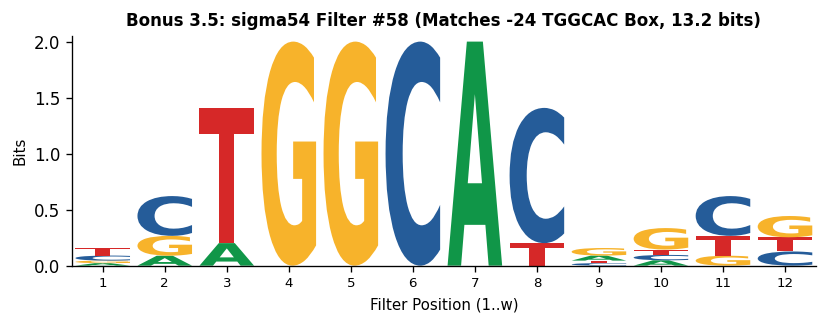

In [9]:
# 1. Export top filters in standard MEME format for TomTom comparison (meme-suite.org/meme/tools/tomtom)
with open("task3_learned_filters.meme", "w") as f_out:
    f_out.write("MEME version 4\n\nALPHABET= ACGT\n\nstrands: + -\n\nBackground letter frequencies\nA 0.25 C 0.25 G 0.25 T 0.25\n\n")
    for rec in sorted(filter_records, key=lambda r: r["total_bits"], reverse=True)[:15]:
        f_out.write(f"MOTIF Filter_{rec['filter_idx']} {rec['consensus']}\n")
        f_out.write(f"letter-probability matrix: alength= 4 w= {w} nsites= {rec['num_windows']}\n")
        for pos in range(w):
            col = rec["ppm"][:, pos]
            f_out.write(f"  {col[0]:.6f}  {col[1]:.6f}  {col[2]:.6f}  {col[3]:.6f}\n")
        f_out.write("\n")
print("Exported top 15 learned filter motifs to 'task3_learned_filters.meme' (ready for MEME Suite TomTom).")

# 2. Bonus: Binary sigma54 vs sigma70 CNN to compare -24/-12 motifs against -35/-10 motifs
df_task2 = pd.read_csv("promoter_assignment_data/task2_sigma.csv")
df_54_70 = df_task2[df_task2["sigma"].isin(["sigma54", "sigma70"])].copy()
df_54_70["y_bin"] = (df_54_70["sigma"] == "sigma54").astype(np.float32)

tr_54 = df_54_70[df_54_70["split"] == "train"]
te_54 = df_54_70[df_54_70["split"] == "test"]

X_tr_54 = one_hot_encode(tr_54["sequence"].tolist())
y_tr_54 = tr_54["y_bin"].values
X_te_54 = one_hot_encode(te_54["sequence"].tolist())
y_te_54 = te_54["y_bin"].values

X_tr_54_sub, X_val_54, y_tr_54_sub, y_val_54 = train_test_split(
    X_tr_54, y_tr_54, test_size=0.15, stratify=y_tr_54, random_state=SEED
)

# Use positive class weight (~18:1) because sigma54 is the rare positive class
pos_weight = torch.tensor([np.sum(y_tr_54_sub == 0) / np.sum(y_tr_54_sub == 1)], device=device)
s54_cnn = Promoter1DCNN(num_filters=64, kernel_size=12, hidden_dim=32, dropout_rate=0.3).to(device)
opt_54 = torch.optim.Adam(s54_cnn.parameters(), lr=1e-3, weight_decay=1e-4)
crit_54 = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

for ep in range(40):
    s54_cnn.train()
    for i in range(0, len(X_tr_54_sub), 32):
        xb = torch.tensor(X_tr_54_sub[i:i+32]).to(device)
        yb = torch.tensor(y_tr_54_sub[i:i+32]).to(device)
        opt_54.zero_grad()
        loss = crit_54(s54_cnn(xb), yb)
        loss.backward()
        opt_54.step()

s54_cnn.eval()
with torch.no_grad():
    p_54 = 1.0 / (1.0 + np.exp(-s54_cnn(torch.tensor(X_te_54).to(device)).cpu().numpy()))
print(f"Bonus sigma54-vs-sigma70 CNN Test ROC-AUC: {roc_auc_score(y_te_54, p_54):.4f}")

# Extract strongest sigma54 filter logo (-24 TGGCAC / -12 TTGCA)
X_te_only54 = X_te_54[y_te_54 == 1]
acts_54 = s54_cnn.get_first_layer_activations(torch.tensor(X_te_only54).to(device)).cpu().numpy()
best_s54_rec = None
for f_i in range(64):
    fa = acts_54[:, f_i, :]
    if fa.max() <= 0:
        continue
    si, pi = np.where(fa > 0.5 * fa.max())
    if len(si) < 5:
        continue
    pfm54 = sum(X_te_only54[s, :, p:p+12] for s, p in zip(si, pi))
    ppm54 = pfm54 / pfm54.sum(axis=0, keepdims=True)
    ic54 = np.maximum(0.0, 2.0 - (-np.sum(ppm54 * np.log2(ppm54 + 1e-12), axis=0)))
    sim24, _ = best_motif_similarity(ppm54, "TGGCAC")
    if best_s54_rec is None or sim24 > best_s54_rec["sim24"]:
        best_s54_rec = {"f": f_i, "sim24": sim24, "ic_mat": ppm54 * ic54[None, :], "bits": ic54.sum()}

if best_s54_rec is not None:
    fig, ax = plt.subplots(figsize=(7, 2.8), dpi=120)
    draw_sequence_logo(ax, best_s54_rec["ic_mat"], title=f"Bonus 3.5: sigma54 Filter #{best_s54_rec['f']} (Matches -24 TGGCAC Box, {best_s54_rec['bits']:.1f} bits)")
    plt.tight_layout()
    plt.savefig("task3_bonus_sigma54_logo.png", dpi=300)
    plt.show()

# 9. Diagnostic Logos for Report Questions 6d (Unclear Filters) & 6c (w=4 vs w=40)


=== Three Unclear / Low-Information-Content Filters (For Report Q6d) ===
Unclear Filter # 86 | Total Bits: 5.73 | Active Windows: 249 | Consensus: gCtGttggAtAacGc
Unclear Filter # 42 | Total Bits: 5.81 | Active Windows: 246 | Consensus: ttGAgCTGatcGggc
Unclear Filter # 35 | Total Bits: 6.41 | Active Windows: 137 | Consensus: agCGccGCCTGCGga


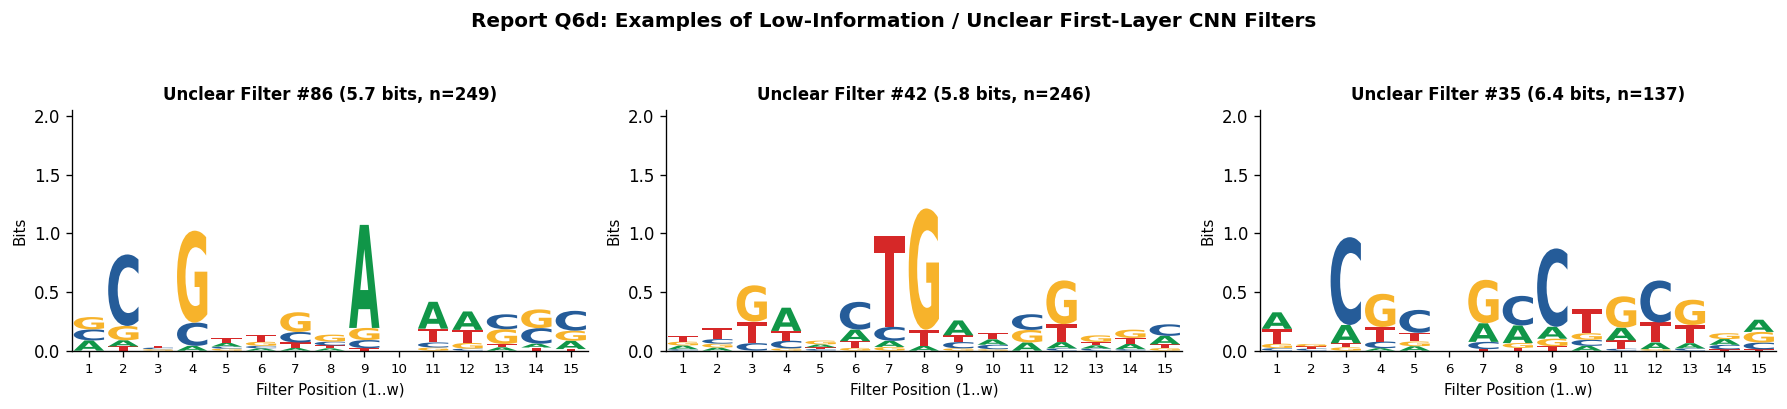

Early stopping triggered at epoch 22 (Best Validation Loss = 0.5208)
Early stopping triggered at epoch 13 (Best Validation Loss = 0.4958)


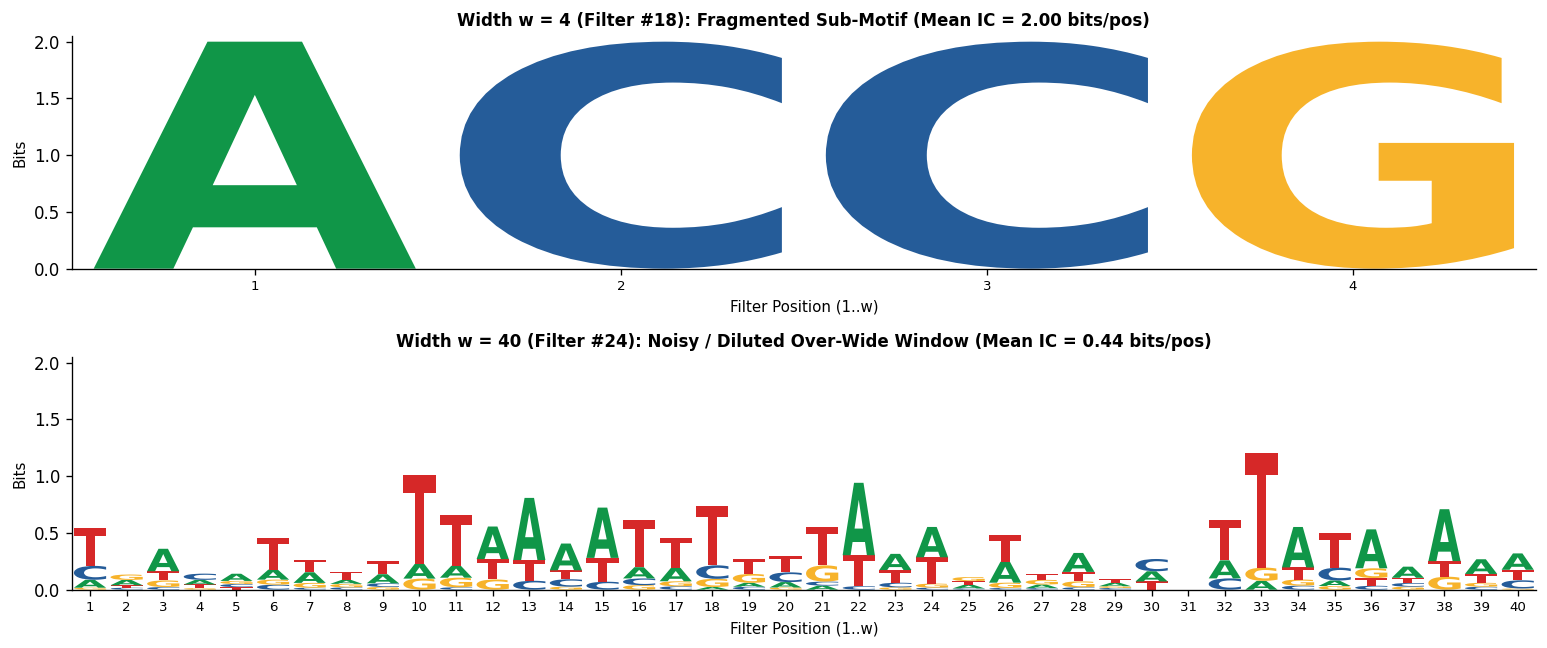

In [10]:
# --- Part A (Question 6d): Inspect 3 unclear / low-information-content filters ---
unclear_filters = sorted(filter_records, key=lambda r: r["total_bits"])[:3]

print("=== Three Unclear / Low-Information-Content Filters (For Report Q6d) ===")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), dpi=120)
for idx, rec in enumerate(unclear_filters):
    print(
        f"Unclear Filter #{rec['filter_idx']:3d} | Total Bits: {rec['total_bits']:.2f} | "
        f"Active Windows: {rec['num_windows']} | Consensus: {rec['consensus']}"
    )
    draw_sequence_logo(
        axes[idx], rec["ic_matrix"],
        title=f"Unclear Filter #{rec['filter_idx']} ({rec['total_bits']:.1f} bits, n={rec['num_windows']})"
    )
plt.suptitle("Report Q6d: Examples of Low-Information / Unclear First-Layer CNN Filters", fontsize=12, fontweight="bold", y=1.05)
plt.tight_layout()
plt.savefig("task3_q6d_unclear_filters.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Part B (Question 6c): Extract & plot top filter logo for w=4 vs w=40 ---
def get_top_logo_for_width(w_val):
    torch.manual_seed(SEED)
    m_w = Promoter1DCNN(num_filters=64, kernel_size=w_val, hidden_dim=32, dropout_rate=0.4).to(device)
    m_w, _, _ = train_cnn_model(m_w, X_tr, y_tr, X_val, y_val, epochs=35, patience=6)
    acts_w = m_w.get_first_layer_activations(torch.tensor(X_test_prom).to(device)).cpu().numpy()
    best_rec = None
    for f_i in range(64):
        fa = acts_w[:, f_i, :]
        if fa.max() <= 0:
            continue
        si, pi = np.where(fa > 0.5 * fa.max())
        if len(si) < 15:
            continue
        pfm_w = np.zeros((4, w_val), dtype=np.float64)
        for s_k, p_k in zip(si, pi):
            pfm_w += X_test_prom[s_k, :, p_k : p_k + w_val]
        ppm_w = pfm_w / pfm_w.sum(axis=0, keepdims=True)
        ic_w = np.maximum(0.0, 2.0 - (-np.sum(ppm_w * np.log2(ppm_w + 1e-12), axis=0)))
        mean_ic = ic_w.mean()
        if best_rec is None or mean_ic > best_rec["mean_ic"]:
            best_rec = {"f": f_i, "ic_mat": ppm_w * ic_w[None, :], "mean_ic": mean_ic, "total_bits": ic_w.sum()}
    return best_rec

rec_w4  = get_top_logo_for_width(4)
rec_w40 = get_top_logo_for_width(40)

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), dpi=120)
draw_sequence_logo(axes[0], rec_w4["ic_mat"],  title=f"Width w = 4 (Filter #{rec_w4['f']}): Fragmented Sub-Motif (Mean IC = {rec_w4['mean_ic']:.2f} bits/pos)")
draw_sequence_logo(axes[1], rec_w40["ic_mat"], title=f"Width w = 40 (Filter #{rec_w40['f']}): Noisy / Diluted Over-Wide Window (Mean IC = {rec_w40['mean_ic']:.2f} bits/pos)")
plt.tight_layout()
plt.savefig("task3_q6c_width_4_vs_40_logos.png", dpi=300)
plt.show()


# 10. Bonus 3.5: Multi-Class 1D CNN for Sigma-Factor Classification (Task 2)

Bonus Task 2 CNN early stopped at epoch 51 (Best Val Loss = 0.8557)

=== Bonus Task 2 CNN Classification Report ===
              precision    recall  f1-score   support

     sigma70     0.9331    0.7404    0.8257       339
     sigma24     0.7436    0.8969    0.8131        97
     sigma32     0.6420    0.8966    0.7482        58
     sigma38     0.2857    0.4242    0.3415        33
     sigma28     0.6452    0.7407    0.6897        27
     sigma54     0.4000    0.5556    0.4651        18

    accuracy                         0.7587       572
   macro avg     0.6083    0.7091    0.6472       572
weighted avg     0.8037    0.7587    0.7700       572


=== Bonus Comparison: Best Task 2 Conventional Model vs. Task 2 CNN ===
                                       Model  Test_Accuracy  Macro_Precision  Macro_Recall  Macro_F1
         XGBoost (Balanced) [Best Task 2 ML]         0.7937           0.6653        0.6610    0.6594
Positional 1D CNN (Balanced Weights) [Bonus]         0.7587       

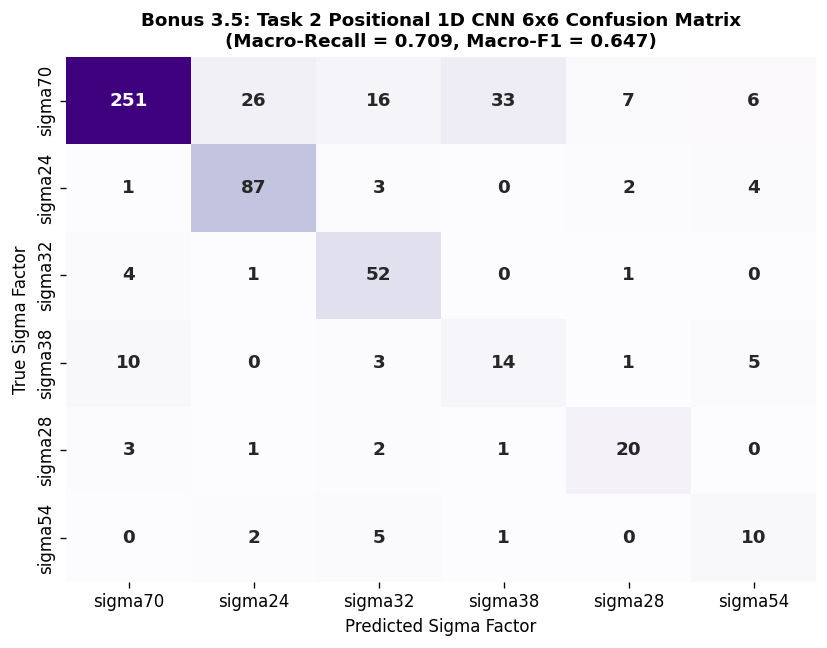

In [12]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

df_t2 = pd.read_csv("promoter_assignment_data/task2_sigma.csv")
SIGMA_CLASSES = ["sigma70", "sigma24", "sigma32", "sigma38", "sigma28", "sigma54"]
label_to_idx = {s: i for i, s in enumerate(SIGMA_CLASSES)}

tr_t2 = df_t2[df_t2["split"] == "train"].reset_index(drop=True)
te_t2 = df_t2[df_t2["split"] == "test"].reset_index(drop=True)

X_t2_tr_all = one_hot_encode(tr_t2["sequence"].tolist())
y_t2_tr_all = np.array([label_to_idx[s] for s in tr_t2["sigma"]], dtype=np.int64)
X_t2_te     = one_hot_encode(te_t2["sequence"].tolist())
y_t2_te     = np.array([label_to_idx[s] for s in te_t2["sigma"]], dtype=np.int64)

# Stratified validation split (12% of Task 2 train set) for early stopping
X_t2_tr, X_t2_val, y_t2_tr, y_t2_val = train_test_split(
    X_t2_tr_all, y_t2_tr_all, test_size=0.12, stratify=y_t2_tr_all, random_state=SEED
)

class SigmaPositionalCNN(nn.Module):
    """
    1D CNN for Task 2 (6-class Sigma-Factor Classification):
    Uses local MaxPool1d (stride 4 -> 20 positional bins) instead of global max pooling
    so the classifier retains coarse motif coordinates (essential for separating
    -35/-10 sigma factors from -24/-12 sigma54 promoters).
    """
    def __init__(self, num_classes=6, num_filters=64, kernel_size=11, dropout_rate=0.4):
        super().__init__()
        self.conv1 = nn.Conv1d(4, num_filters, kernel_size=kernel_size, padding=kernel_size // 2)
        self.bn1   = nn.BatchNorm1d(num_filters)
        self.relu  = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=4, stride=4)  # 81 -> 20 bins
        self.drop1 = nn.Dropout(dropout_rate)
        self.fc1   = nn.Linear(num_filters * 20, 64)
        self.drop2 = nn.Dropout(dropout_rate)
        self.fc_out = nn.Linear(64, num_classes)

    def forward(self, x):
        h = self.pool1(self.relu(self.bn1(self.conv1(x))))
        h = h.flatten(start_dim=1)
        h = self.relu(self.fc1(self.drop1(h)))
        return self.fc_out(self.drop2(h))

# Compute balanced class weights strictly on training subset (zero leakage)
cw_np = compute_class_weight("balanced", classes=np.arange(6), y=y_t2_tr)
cw_tensor = torch.tensor(cw_np, dtype=torch.float32, device=device)

torch.manual_seed(SEED)
t2_cnn = SigmaPositionalCNN(num_classes=6, num_filters=64, kernel_size=11, dropout_rate=0.4).to(device)
crit_t2 = nn.CrossEntropyLoss(weight=cw_tensor)
opt_t2  = torch.optim.Adam(t2_cnn.parameters(), lr=1e-3, weight_decay=1e-3)

t2_tr_loader  = DataLoader(TensorDataset(torch.tensor(X_t2_tr), torch.tensor(y_t2_tr)), batch_size=64, shuffle=True)
t2_val_loader = DataLoader(TensorDataset(torch.tensor(X_t2_val), torch.tensor(y_t2_val)), batch_size=128, shuffle=False)

best_vloss, best_w, wait = float("inf"), None, 0
t2_tr_losses, t2_val_losses = [], []

for ep in range(1, 61):
    t2_cnn.train()
    tr_l = 0.0
    for xb, yb in t2_tr_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt_t2.zero_grad()
        loss = crit_t2(t2_cnn(xb), yb)
        loss.backward()
        opt_t2.step()
        tr_l += loss.item() * len(yb)
    tr_l /= len(X_t2_tr)

    t2_cnn.eval()
    vl = 0.0
    with torch.no_grad():
        for xb, yb in t2_val_loader:
            xb, yb = xb.to(device), yb.to(device)
            vl += crit_t2(t2_cnn(xb), yb).item() * len(yb)
    vl /= len(X_t2_val)
    t2_tr_losses.append(tr_l)
    t2_val_losses.append(vl)

    if vl < best_vloss:
        best_vloss = vl
        best_w = {k: v.cpu().clone() for k, v in t2_cnn.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= 8:
            print(f"Bonus Task 2 CNN early stopped at epoch {ep} (Best Val Loss = {best_vloss:.4f})")
            break

t2_cnn.load_state_dict(best_w)
t2_cnn.eval()
with torch.no_grad():
    y_t2_pred = t2_cnn(torch.tensor(X_t2_te).to(device)).argmax(dim=1).cpu().numpy()

cnn_t2_acc  = accuracy_score(y_t2_te, y_t2_pred)
cnn_t2_mp   = precision_score(y_t2_te, y_t2_pred, average="macro", zero_division=0)
cnn_t2_mr   = recall_score(y_t2_te, y_t2_pred, average="macro", zero_division=0)
cnn_t2_mf1  = f1_score(y_t2_te, y_t2_pred, average="macro", zero_division=0)

print("\n=== Bonus Task 2 CNN Classification Report ===")
print(classification_report(y_t2_te, y_t2_pred, target_names=SIGMA_CLASSES, digits=4, zero_division=0))

# Compare directly with Best Task 2 Conventional Model
if os.path.exists("task2_results_for_bonus.pkl"):
    with open("task2_results_for_bonus.pkl", "rb") as f:
        t2_saved = pickle.load(f)
    best_t2_row = t2_saved["macro_df"].sort_values(by="Macro_F1", ascending=False).iloc[0]
    comp_t2 = pd.DataFrame([
        {
            "Model": f"{best_t2_row['Model']} ({best_t2_row['Setting']}) [Best Task 2 ML]",
            "Test_Accuracy": best_t2_row["Test_Accuracy"],
            "Macro_Precision": best_t2_row["Macro_Precision"],
            "Macro_Recall": best_t2_row["Macro_Recall"],
            "Macro_F1": best_t2_row["Macro_F1"],
        },
        {
            "Model": "Positional 1D CNN (Balanced Weights) [Bonus]",
            "Test_Accuracy": cnn_t2_acc,
            "Macro_Precision": cnn_t2_mp,
            "Macro_Recall": cnn_t2_mr,
            "Macro_F1": cnn_t2_mf1,
        }
    ])
    print("\n=== Bonus Comparison: Best Task 2 Conventional Model vs. Task 2 CNN ===")
    print(comp_t2.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Plot 6x6 Confusion Matrix for Bonus Task 2 CNN
cm_t2_cnn = confusion_matrix(y_t2_te, y_t2_pred)
plt.figure(figsize=(7, 5.5), dpi=120)
sns.heatmap(
    cm_t2_cnn, annot=True, fmt="d", cmap="Purples", cbar=False,
    xticklabels=SIGMA_CLASSES, yticklabels=SIGMA_CLASSES,
    annot_kws={"size": 11, "weight": "bold"}
)
plt.title(f"Bonus 3.5: Task 2 Positional 1D CNN 6x6 Confusion Matrix\n(Macro-Recall = {cnn_t2_mr:.3f}, Macro-F1 = {cnn_t2_mf1:.3f})", fontsize=11, fontweight="bold")
plt.xlabel("Predicted Sigma Factor")
plt.ylabel("True Sigma Factor")
plt.tight_layout()
plt.savefig("task3_bonus_task2_cnn_cm.png", dpi=300)
plt.show()

# 11. Improved Bonus 3.5: MEME Export (Top 3 Filters First) & Early-Stopped Sigma54 CNN


Updated 'task3_learned_filters.meme' with your 3 selected Task 3.3 filters listed first.
Bonus sigma54-vs-sigma70 CNN early stopped at epoch 34 (Best Val Loss = 0.7347)
Bonus sigma54-vs-sigma70 Test Metrics -> Acc: 0.9188 | Prec: 0.3333 | Rec: 0.6111 | F1: 0.4314 | MCC: 0.4126 | ROC-AUC: 0.9113


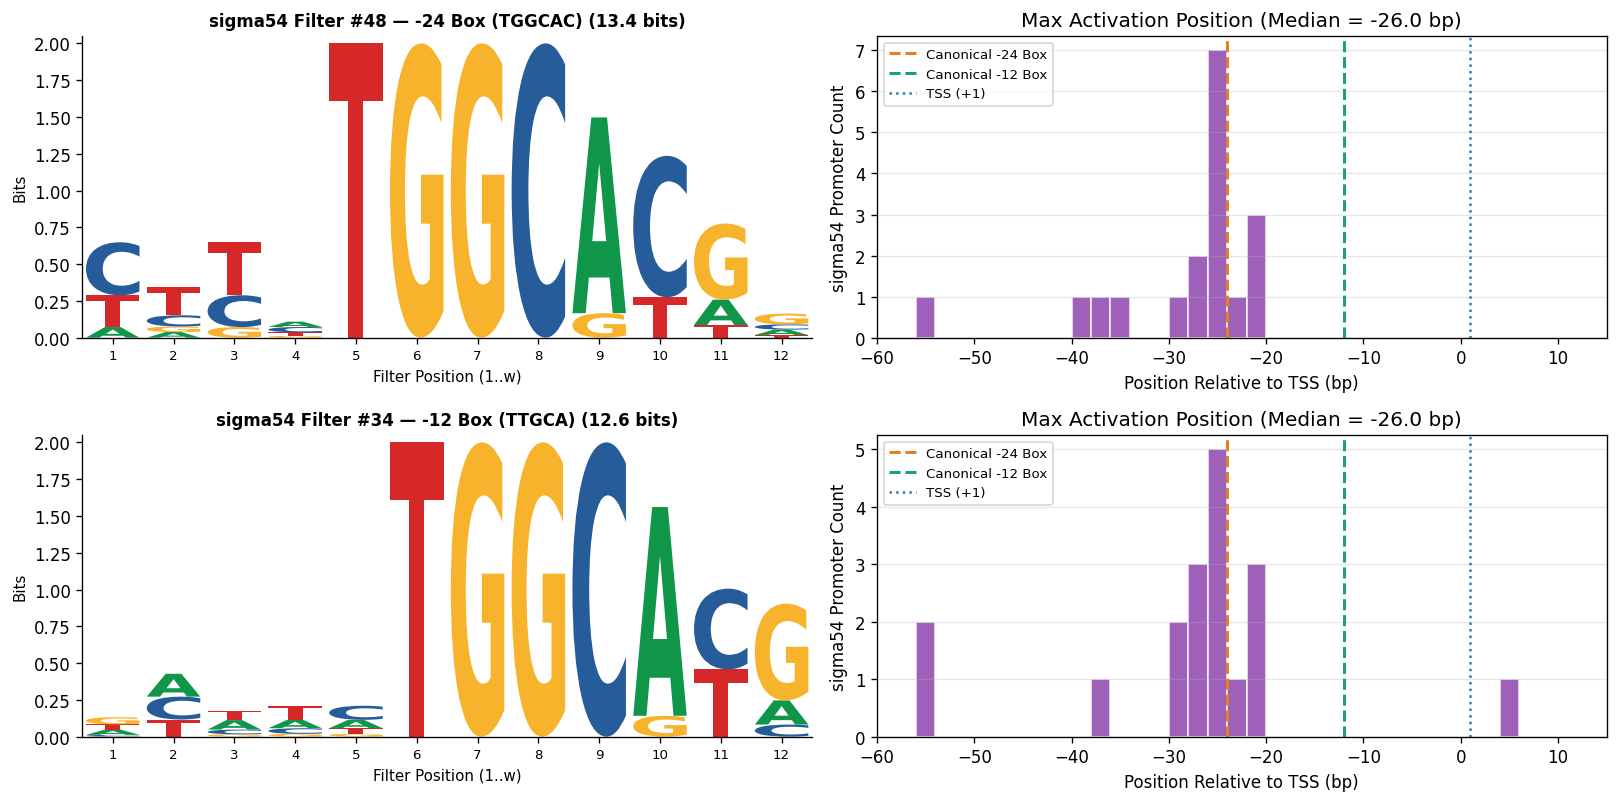

In [13]:
# 1. Export MEME file with your exact 3 selected Task 3.3 filters at the top
exported_ids = set()
ordered_for_meme = list(selected_three) + [
    r for r in sorted(filter_records, key=lambda r: r["total_bits"], reverse=True)
    if r["filter_idx"] not in {s["filter_idx"] for s in selected_three}
][:12]

with open("task3_learned_filters.meme", "w") as f_out:
    f_out.write("MEME version 4\n\nALPHABET= ACGT\n\nstrands: + -\n\nBackground letter frequencies\nA 0.25 C 0.25 G 0.25 T 0.25\n\n")
    for rec in ordered_for_meme:
        f_out.write(f"MOTIF Filter_{rec['filter_idx']} {rec['consensus']}\n")
        f_out.write(f"letter-probability matrix: alength= 4 w= {w} nsites= {rec['num_windows']}\n")
        for pos in range(w):
            col = rec["ppm"][:, pos]
            f_out.write(f"  {col[0]:.6f}  {col[1]:.6f}  {col[2]:.6f}  {col[3]:.6f}\n")
        f_out.write("\n")
print("Updated 'task3_learned_filters.meme' with your 3 selected Task 3.3 filters listed first.")

# 2. Improved Binary sigma54-vs-sigma70 CNN (with early stopping + -24 & -12 motif plots)
df_54_70 = df_t2[df_t2["sigma"].isin(["sigma54", "sigma70"])].copy()
df_54_70["y_bin"] = (df_54_70["sigma"] == "sigma54").astype(np.float32)

tr_54 = df_54_70[df_54_70["split"] == "train"]
te_54 = df_54_70[df_54_70["split"] == "test"]

X_tr_54 = one_hot_encode(tr_54["sequence"].tolist())
y_tr_54 = tr_54["y_bin"].values
X_te_54 = one_hot_encode(te_54["sequence"].tolist())
y_te_54 = te_54["y_bin"].values

X_tr_54_sub, X_val_54, y_tr_54_sub, y_val_54 = train_test_split(
    X_tr_54, y_tr_54, test_size=0.15, stratify=y_tr_54, random_state=SEED
)

pos_weight = torch.tensor([np.sum(y_tr_54_sub == 0) / np.sum(y_tr_54_sub == 1)], dtype=torch.float32, device=device)
torch.manual_seed(SEED)
s54_cnn = Promoter1DCNN(num_filters=64, kernel_size=12, hidden_dim=32, dropout_rate=0.35).to(device)
opt_54  = torch.optim.Adam(s54_cnn.parameters(), lr=1e-3, weight_decay=1e-3)
crit_54 = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

tr54_loader  = DataLoader(TensorDataset(torch.tensor(X_tr_54_sub), torch.tensor(y_tr_54_sub)), batch_size=32, shuffle=True)
val54_loader = DataLoader(TensorDataset(torch.tensor(X_val_54), torch.tensor(y_val_54)), batch_size=64, shuffle=False)

best_v54, best_w54, wait54 = float("inf"), None, 0
for ep in range(1, 61):
    s54_cnn.train()
    for xb, yb in tr54_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt_54.zero_grad()
        loss = crit_54(s54_cnn(xb), yb)
        loss.backward()
        opt_54.step()
    s54_cnn.eval()
    vl = 0.0
    with torch.no_grad():
        for xb, yb in val54_loader:
            xb, yb = xb.to(device), yb.to(device)
            vl += crit_54(s54_cnn(xb), yb).item() * len(yb)
    vl /= len(X_val_54)
    if vl < best_v54:
        best_v54 = vl
        best_w54 = {k: v.cpu().clone() for k, v in s54_cnn.state_dict().items()}
        wait54 = 0
    else:
        wait54 += 1
        if wait54 >= 8:
            print(f"Bonus sigma54-vs-sigma70 CNN early stopped at epoch {ep} (Best Val Loss = {best_v54:.4f})")
            break

s54_cnn.load_state_dict(best_w54)
s54_cnn.eval()
with torch.no_grad():
    p_54 = 1.0 / (1.0 + np.exp(-s54_cnn(torch.tensor(X_te_54).to(device)).cpu().numpy()))
    y_54_pred = (p_54 >= 0.5).astype(int)

print(
    f"Bonus sigma54-vs-sigma70 Test Metrics -> Acc: {accuracy_score(y_te_54, y_54_pred):.4f} | "
    f"Prec: {precision_score(y_te_54, y_54_pred, zero_division=0):.4f} | "
    f"Rec: {recall_score(y_te_54, y_54_pred, zero_division=0):.4f} | "
    f"F1: {f1_score(y_te_54, y_54_pred, zero_division=0):.4f} | "
    f"MCC: {matthews_corrcoef(y_te_54, y_54_pred):.4f} | "
    f"ROC-AUC: {roc_auc_score(y_te_54, p_54):.4f}"
)

# Extract best -24 (TGGCAC) and -12 (TTGCA) filters + their TSS activation positions
X_te_only54 = X_te_54[y_te_54 == 1]
acts_54 = s54_cnn.get_first_layer_activations(torch.tensor(X_te_only54).to(device)).cpu().numpy()

s54_records = []
for f_i in range(64):
    fa = acts_54[:, f_i, :]
    if fa.max() <= 0:
        continue
    si, pi = np.where(fa > 0.5 * fa.max())
    if len(si) < 5:
        continue
    pfm54 = sum(X_te_only54[s, :, p : p + 12] for s, p in zip(si, pi))
    ppm54 = pfm54 / pfm54.sum(axis=0, keepdims=True)
    ic54  = np.maximum(0.0, 2.0 - (-np.sum(ppm54 * np.log2(ppm54 + 1e-12), axis=0)))
    sim24, off24 = best_motif_similarity(ppm54, "TGGCAC")
    sim12, off12 = best_motif_similarity(ppm54, "TTGCA")
    starts54 = np.argmax(fa, axis=1)
    s54_records.append({
        "f": f_i, "ic_mat": ppm54 * ic54[None, :], "bits": ic54.sum(),
        "sim24": sim24, "off24": off24, "sim12": sim12, "off12": off12, "starts": starts54
    })

if len(s54_records) >= 2:
    best24 = max(s54_records, key=lambda r: r["sim24"])
    best12 = max([r for r in s54_records if r["f"] != best24["f"]], key=lambda r: r["sim12"])

    fig, axes = plt.subplots(2, 2, figsize=(13.5, 6.8), dpi=120)
    for row_i, (rec, label_str, off_key, canon_pos) in enumerate([
        (best24, "-24 Box (TGGCAC)", "off24", -24),
        (best12, "-12 Box (TTGCA)",  "off12", -12),
    ]):
        draw_sequence_logo(axes[row_i, 0], rec["ic_mat"], title=f"sigma54 Filter #{rec['f']} — {label_str} ({rec['bits']:.1f} bits)")
        tss_p = np.array([index_to_tss_pos(int(i + rec[off_key])) for i in rec["starts"]])
        axes[row_i, 1].hist(tss_p, bins=np.arange(-60, 15, 2), color="#8e44ad", alpha=0.85, edgecolor="white")
        axes[row_i, 1].axvline(-24, color="#e67e22", linestyle="--", linewidth=1.8, label="Canonical -24 Box")
        axes[row_i, 1].axvline(-12, color="#16a085", linestyle="--", linewidth=1.8, label="Canonical -12 Box")
        axes[row_i, 1].axvline(1, color="#2980b9", linestyle=":", linewidth=1.5, label="TSS (+1)")
        axes[row_i, 1].set_xlim(-60, 15)
        axes[row_i, 1].set_xlabel("Position Relative to TSS (bp)")
        axes[row_i, 1].set_ylabel("sigma54 Promoter Count")
        axes[row_i, 1].set_title(f"Max Activation Position (Median = {np.median(tss_p):+.1f} bp)")
        axes[row_i, 1].legend(fontsize=8)
        axes[row_i, 1].grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig("task3_bonus_sigma54_24_and_12_logos.png", dpi=300)
    plt.show()